## Output Analysis Development
Use this notebook for initial assessment of model output and development of automated analysis scripts.

In [2]:
path_env = 'desktop'  # Change this to 'desktop' or 'alpine' as needed

In [3]:
import os

# Configure environmental variables
if path_env == 'desktop':
    os.environ['OUTPUT_PATH'] = 'C:/Users/clmbn/NMT_PhD/data/output' #desktop
    os.environ['SNOTEL_PATH'] = 'C:/Users/clmbn/NMT_PhD/data/snotel/' #desktop
    os.environ['FORCING_PATH'] = 'C:/Users/clmbn/NMT_PhD/data/forcing/' #desktop
elif path_env == 'alpine':
    os.environ['OUTPUT_PATH'] = r'/projects/ccox1@xsede.org/lm4px_modelling/output' #Alpine
    os.environ['SNOTEL_PATH'] = r'/projects/ccox1@xsede.org/data/snotel/'
    os.environ['FORCING_PATH'] = r'/projects/ccox1@xsede.org/data/forcing/'
else:
    raise ValueError("Invalid path_env. Choose 'desktop' or 'alpine'.")

In [4]:
%matplotlib ipympl
import xarray as xr
import matplotlib.pyplot as plt
import pandas as pd
from model_datasets.forcing import LM4Forcing
from model_datasets.output import LM4ModelOutput 
from buildforcing.datasets import PNNLSnotel

Load datasets

In [5]:
forcing = LM4Forcing(site='Quemazon', forcing_string='00000010', version='0.2', spinup=False)
forcing2 = LM4Forcing(site='Quemazon', forcing_string='00000000', version='0.2', spinup=False)

In [13]:
model = LM4ModelOutput(site='Quemazon', forcing_string='00000010', version='0.2', spinup=False)
model2 = LM4ModelOutput(site='Quemazon', forcing_string='00000000', version='0.2', spinup=False)

In [8]:
daily_vars = model.get_variables(diag='land_daily')

In [9]:
monthly_vars = model.get_variables(diag='land_month')

In [10]:
snotel = PNNLSnotel('Quemazon', os.environ['SNOTEL_PATH'])
snotel.load_data()

In [11]:
snotel_data = snotel.data

# Remove timezone from index
snotel_data.index = snotel_data.index.tz_localize(None)

### Snow

In [14]:
model_snow = model.get_data(['snow','snow_depth'],'land_daily')
model2_snow = model2.get_data(['snow','snow_depth'],'land_daily')

In [15]:
snotel.data.head()

,T_max_C,T_min_C,T_avg_C,precip_mm,swe_mm
Date,,,,,
1980-06-04,NaN,NaN,NaN,0.0,NaN
1980-06-05,NaN,NaN,NaN,0.0,NaN
1980-06-06,NaN,NaN,NaN,0.0,NaN
1980-06-07,NaN,NaN,NaN,0.0,NaN
1980-06-08,NaN,NaN,NaN,0.0,NaN


In [16]:
# Get range of dates for plotting
start_date = model_snow.index[0]
end_date = model_snow.index[-1]

In [17]:
snotel.data.index

DatetimeIndex(['1980-06-04', '1980-06-05', '1980-06-06', '1980-06-07',
               '1980-06-08', '1980-06-09', '1980-06-10', '1980-06-11',
               '1980-06-12', '1980-06-13',
               ...
               '2021-09-21', '2021-09-22', '2021-09-23', '2021-09-24',
               '2021-09-25', '2021-09-26', '2021-09-27', '2021-09-28',
               '2021-09-29', '2021-09-30'],
              dtype='datetime64[ns]', name='Date', length=15094, freq=None)

In [18]:
Tair = forcing.get_data('Tair')
Snowfall = forcing.get_data('Snowf')

Tair = Tair - 273.15  # Convert from Kelvin to Celsius

Tair_daily = Tair.resample('D').mean()
forcing_snow = Snowfall.resample('D').sum()

In [19]:
Tair2 = forcing2.get_data('Tair')
Snowfall2 = forcing2.get_data('Snowf')

Tair2 = Tair2 - 273.15  # Convert from Kelvin to Celsius

Tair_daily2 = Tair2.resample('D').mean()
forcing_snow2 = Snowfall2.resample('D').sum()

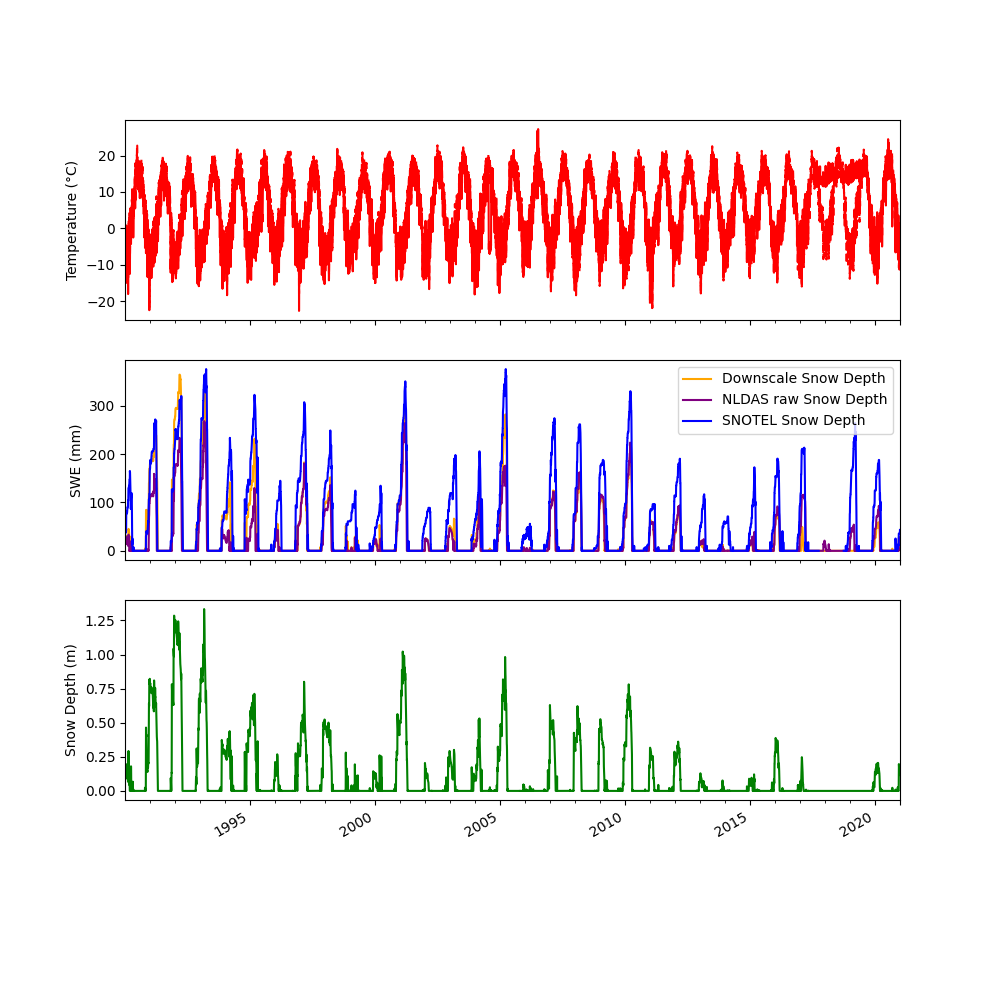

In [22]:
# Plot snow
fig, ax = plt.subplots(3, 1, figsize=(10, 10), sharex=True)
Tair_daily.plot(ax=ax[0], label='Tair (Daily Mean)', color='red')
Tair_daily2.plot(ax=ax[0], label='Tair2 (Daily Mean)', style='--', color='red')
model_snow['snow'].plot(ax=ax[1], label='Downscale Snow Depth', color='orange')
model2_snow['snow'].plot(ax=ax[1], label='NLDAS raw Snow Depth', color='purple')
snotel_data.loc[start_date:end_date, 'swe_mm'].plot(ax=ax[1], label='SNOTEL Snow Depth', color='blue')
model_snow['snow_depth'].plot(ax=ax[2], label='Model Snow Depth (Depth)', color='green')
ax[0].set_ylabel('Temperature (°C)')
ax[1].set_ylabel('SWE (mm)')
ax[2].set_ylabel('Snow Depth (m)')
ax[1].legend()

### Vegetation

### Soil Temperature

In [ ]:
spinup_soil = spinup.get_data(['soil_T'], diag='land_daily')

In [ ]:
# Change data in soil dataframes to celsius
spinup_soil = spinup_soil - 273.15

In [ ]:
# Plot snow, Tair, and soil temperatures at 0.04, 1.20, 5.50m
fig, ax = plt.subplots(5, 1, figsize=(15, 10), sharex=True)
spinup_snow['snow_depth'].plot(ax=ax[0], label='CM Snow Depth', color='blue')
Tair.plot(ax=ax[1], label='Tair', color='black')
spinup_soil['soil_T 0.04'].plot(ax=ax[2], label='CM Soil T 0.04m', color='blue')
spinup_soil['soil_T 1.20'].plot(ax=ax[3], label='CM Soil T 1.20m', color='blue')
spinup_soil['soil_T 5.50'].plot(ax=ax[4], label='CM Soil T 5.50m', color='blue')

#### Soil liquid/ice water content
These variables are currently in monthly data.

In [ ]:
spinup_soil_water = spinup.get_data(['soil_liq'], diag='land_month')

In [ ]:
Tair_month = Tair.resample('MS').mean()

# Shift index forward 15 days to match the land month data
Tair_month.index = Tair_month.index + pd.DateOffset(days=15)

In [ ]:
# Plot soil water content for both models at depths 0.04, 1.20, 5.50 and 8.75m
fig, ax = plt.subplots(4, 1, figsize=(15, 10), sharex=True)
spinup_soil_water.loc[start_date:end_date, 'soil_liq 0.04'].plot(ax=ax[0], label='CM Soil Liq 0.04m', color='blue')
spinup_soil_water.loc[start_date:end_date, 'soil_liq 1.20'].plot(ax=ax[1], label='CM Soil Liq 1.20m', color='blue')
spinup_soil_water.loc[start_date:end_date, 'soil_liq 5.50'].plot(ax=ax[2], label='CM Soil Liq 5.50m', color='blue')
spinup_soil_water.loc[start_date:end_date, 'soil_liq 8.75'].plot(ax=ax[3], label='CM Soil Liq 8.75m', color='blue')